# Python for AI — Class 22
### Neural Networks in PyTorch: build and train a real network

Last class you trained a neuron **by hand**: you wrote the forward pass, the loss and the steps downhill yourself.

Today we use **PyTorch**, the library that real AI companies use (it was made by Meta, Facebook's company). It does the hard parts for us:
it calculates which way is downhill for **every** weight (backpropagation), with one line.

At the end, we train a real network to **predict house prices**, and compare it with Linear Regression from Class 18.

## How we will learn today

| Step | What happens |
|------|--------------|
| **CONCEPT** | The teacher explains the idea. Short points. |
| **EXAMPLE** | The teacher types the code. **You type it too** and run it. |
| **QUICK CHECK** | You solve a small task alone. |
| **🧑‍🏫 CLASS PROBLEM** | At the end, we solve one real problem **together**, step by step. |
| **🏠 HOME PROBLEM** | You solve the **same kind of problem** alone, on new data. Bring it to the next class. |

The solutions are in a separate file.

**Tip:** Run a cell with `Shift + Enter`.

## New words today

Don't worry if they are new. We will explain each one with an example.

| Word | Meaning in simple words |
|------|-------------------------|
| **PyTorch** | a Python library for building and training neural networks |
| **Tensor** | PyTorch's array. Like a NumPy array, but it can also calculate gradients |
| **Gradient** | which way is downhill for a weight (and how steep) |
| **nn.Linear** | a layer of neurons: inputs × weights + bias |
| **nn.Sequential** | puts layers in a row to make a network |
| **Optimizer** | the part that takes the steps downhill (changes the weights) |
| **Validation data** | a "mock exam": data we check during training, to see if the model is overfitting |
| **Loss curve** | a chart of the loss after each epoch. It shows how training went |

# Hour 1: Tensors and Building a Network

## CONCEPT: What is a tensor?

- A **tensor** is PyTorch's version of a NumPy array. Same idea: numbers in rows and columns, with a **shape**.
- Maths works the same way: `+`, `*`, `.mean()`, `@`...
- **The special power:** a tensor can **remember the calculations** done with it, and then find the **gradient**: which way each number should change to make the loss smaller. That is the "which way is downhill" from Class 21, done automatically.
- Neural networks use **decimal numbers** (`float32`). So we always make tensors with `dtype=torch.float32`.

## Get started
**Using Colab?** The CSV files are in the same folder as this notebook. In Colab, click the **folder icon** on the left → **upload** the CSV files first.

In [3]:
# On your own laptop, install once:  pip install torch scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

sns.set_theme(style="whitegrid")
torch.manual_seed(42)        # the same "random" starting weights for everyone

### EXAMPLE: Tensors are like NumPy arrays

In [4]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([10.0, 20.0, 30.0])

print(a + b)            # element by element, like NumPy
print(a * 2)
print(a.mean())
print(a.shape)

tensor([11., 22., 33.])
tensor([2., 4., 6.])
tensor(2.)
torch.Size([3])


In [31]:
# From a Pandas table to a tensor
students = pd.read_csv("students_100.csv")

x = torch.tensor(students["study_hours"].values, dtype=torch.float32).reshape(-1, 1)
y = torch.tensor(students["maths"].values, dtype=torch.float32).reshape(-1, 1)
print(x.shape, y.shape)

torch.Size([100, 1]) torch.Size([100, 1])


`.reshape(-1, 1)` makes it **one column** with many rows: shape `(100, 1)`. Networks want the data like a table: one row per example, one column per feature. (`-1` means "work out the number of rows yourself", like in Class 13.)

## CONCEPT: PyTorch finds the gradient for us

Remember the hill from Class 21. To take a step, we need to know **which way is downhill** for each weight.

- Make the weight with `requires_grad=True`: "**please track this number**".
- Calculate the loss.
- Call `loss.backward()`. PyTorch goes **back** through the calculation (**backpropagation**!) and puts the gradient in `w.grad`.
- `w.grad` **negative** → making `w` **bigger** makes the loss smaller. **Positive** → make `w` smaller.

### EXAMPLE: One weight, one gradient

In [26]:
w = torch.tensor(2.0, requires_grad=True)   # our weight. Track it!

# A tiny problem: input 3, we want the output 12. So the best w is 4.
prediction = w * 3
loss = (prediction - 12) ** 2               # (6 - 12)² = 36

loss.backward()                             # backpropagation: find the gradient
print("loss:", loss.item())
print("gradient of w:", w.grad.item())

loss: 36.0
gradient of w: -36.0


The gradient is **−36**: negative, so PyTorch says **"make w bigger"**. That's right: w = 2 is too small, the best is 4.

We didn't write any formula. In Class 21 we needed `(2 * error * x).mean()`. Here, `.backward()` did it, and it works for **millions** of weights in the same way.

### ✏️ QUICK CHECK 1: Tensors

1) Make a tensor `marks` with the values `[80, 72, 91, 65]` (as decimals). Print its mean and its shape.
2) Make `w = torch.tensor(5.0, requires_grad=True)`, calculate `loss = (w * 3 - 12) ** 2`, call `loss.backward()` and print `w.grad`.
   Is it positive or negative? Should w go up or down?

Write your code in the cell below.

In [7]:
# Write your code here

## CONCEPT: Building a network with layers

- `nn.Linear(inputs, outputs)` = a **layer** of neurons. Each neuron: inputs × weights + bias.
  - `nn.Linear(1, 1)` = **one neuron** with 1 input. Exactly the `w * x + b` from Class 21!
- `nn.ReLU()` = the ReLU activation (negative → 0).
- `nn.Sequential(...)` = put the layers **in a row**. The data goes through them in order (the forward pass).

```python
model = nn.Sequential(
    nn.Linear(4, 8),    # 4 inputs  → 8 hidden neurons
    nn.ReLU(),          # activation
    nn.Linear(8, 1),    # 8 hidden  → 1 output (the price)
)
```

```
 4 inputs           8 hidden neurons (ReLU)          1 output
 size      ─┐       ( ) ( ) ( ) ( )
 bedrooms  ─┼──▶    ( ) ( ) ( ) ( )        ──▶       price
 age       ─┤
 distance  ─┘
```

### EXAMPLE: Build it and count the weights

In [1]:
model = nn.Sequential(
    nn.Linear(4, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
)
print(model)

n_weights = sum(p.numel() for p in model.parameters())
print("Number of weights and biases:", n_weights)

NameError: name 'nn' is not defined

**49 numbers to learn:**
- Layer 1: 4 inputs × 8 neurons = 32 weights, + 8 biases = 40
- Layer 2: 8 × 1 = 8 weights, + 1 bias = 9
- Total = 40 + 9 = **49**

The weights start **random**. The network knows nothing yet. Training will fix them.

# Hour 2: The Training Loop

## CONCEPT: The training loop in 5 steps

Every PyTorch training, small or huge, has the **same 5 lines** inside a loop:

```python
for epoch in range(epochs):
    prediction = model(x)              # 1. forward pass: guess
    loss = loss_fn(prediction, y)      # 2. how wrong? (the loss)
    optimizer.zero_grad()              # 3. clear the old gradients
    loss.backward()                    # 4. backpropagation: find the new gradients
    optimizer.step()                   # 5. take one step downhill (change all weights)
```

| Step | Same as in Class 21 |
|------|---------------------|
| 1. `model(x)` | `prediction = w * x + b` |
| 2. `loss_fn` | `(error ** 2).mean()` (MSE) |
| 3. `zero_grad()` | (new) PyTorch **adds up** gradients, so we must clear the old ones first |
| 4. `loss.backward()` | the "which way is downhill" calculation, now **automatic** |
| 5. `optimizer.step()` | `w = w - learning_rate * gradient` |

Two new helpers:
- `loss_fn = nn.MSELoss()`: the loss (MSE) from Class 20.
- `optimizer = torch.optim.SGD(model.parameters(), lr=0.05)`: takes the steps. **SGD** = plain gradient descent. `lr` = the learning rate.

### EXAMPLE: Learn the Class 16 line again, with PyTorch

In [ ]:
torch.manual_seed(42)
neuron = nn.Linear(1, 1)                                  # one neuron: w * x + b
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(neuron.parameters(), lr=0.05)


for epoch in range(2000):
    prediction = neuron(x)              # 1. guess
    loss = loss_fn(prediction, y)       # 2. how wrong
    optimizer.zero_grad()               # 3. clear old gradients
    loss.backward()                     # 4. find gradients
    optimizer.step()                    # 5. step downhill

    if epoch % 400 == 0:                # print every 400 epochs
        print(f"epoch {epoch:4}: loss = {loss.item():8.1f}")

print("w =", round(neuron.weight.item(), 2), "  b =", round(neuron.bias.item(), 2))

epoch    0: loss =   2729.1
epoch  400: loss =     70.5
epoch  800: loss =     70.5
epoch 1200: loss =     70.5
epoch 1600: loss =     70.5
w = 9.19   b = 28.09


**The same line again:** `maths = 9.19 × study_hours + 28.09`. The same answer as `np.polyfit` (Class 16) and our hand-made gradient descent (Class 21). Three ways, one line.

- `.item()` takes the number out of a tensor.
- `epoch % 400 == 0` is true at epochs 0, 400, 800... (`%` = the remainder, from Week 1).

### ✏️ QUICK CHECK 2: A smaller learning rate

Copy the example, but use `lr=0.001`. Train for 2000 epochs. Print `w` and `b` at the end.

Did it reach 9.19 and 28.09? Why not?

Write your code in the cell below.

In [10]:
# Write your code here

# Hour 3: Train, Validation, Test, and Loss Curves

## CONCEPT: Three parts of the data

Until now we had 2 parts: train and test. With neural networks we use **3**:

| Part | Like at school | What we use it for |
|------|----------------|--------------------|
| **Train** (60%) | homework | the network **learns** from it |
| **Validation** (20%) | a **mock exam** | we check it **during** training: is it still improving, or overfitting? |
| **Test** (20%) | the **final board exam** | we check it **only once, at the end** |

Why the extra mock exam? During training we make choices: how many epochs, which learning rate... If we made those choices using the test data, the test would not be "new" anymore. So we make the choices with the **validation** data, and keep the test data **untouched** until the end.

## CONCEPT: Reading loss curves

After each epoch, we save the **train loss** and the **validation loss**, and draw them. The shape tells you what happened:

```
 1. GOOD                      2. OVERFITTING                3. LEARNING RATE TOO BIG
 loss                         loss                          loss
  │\                           │\           __/ validation   │  /\    /\  /\
  │ \                          │ \      ___/                 │ /  \  /  \/  \/\
  │  \_____  validation        │  \____/                      │/    \/
  │   \_____ train             │   \_______ train             │
  └────────── epochs           └─────────────── epochs       └────────────── epochs
 both go down and flatten.    validation goes UP again:    the loss jumps around
 The two lines stay close.    memorising! Stop earlier.    or explodes. Use a smaller lr.
```

## CONCEPT: Two more things for real data

- **Scale the features** with `StandardScaler`, like for KNN in Class 19. Networks learn much better when all inputs have the same size.
- **Adam** is a smarter optimizer than SGD: it **changes the step size by itself** for each weight. Most people start with Adam: `torch.optim.Adam(model.parameters(), lr=0.1)`.
- When we only **guess** (not learn), we write `with torch.no_grad():`. It tells PyTorch: "no learning here, don't track the gradients". It is faster and saves memory.

# 🧑‍🏫 Class Problem: House prices with a neural network

**The problem:** In Class 18, Linear Regression predicted Lahore house prices, wrong by about 12 lakh on average. The property dealer asks:
> "Everyone talks about neural networks. Would a neural network be better?"

We find out **together**, step by step.

### Step 1: Load the data

In [1]:
houses = pd.read_csv("houses.csv")
X = houses[["size_marla", "bedrooms", "age_years", "distance_km"]].values
y = houses["price_lakh"].values
print(X.shape, y.shape)

NameError: name 'pd' is not defined

### Step 2: Split into train (60%), validation (20%) and test (20%)

We split two times: first take out the test part, then split the rest into train and validation.

In [12]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)   # 25% of 80% = 20%

print("train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))

train: 120  validation: 40  test: 40


### Step 3: Scale, and make tensors

In [13]:
scaler = StandardScaler().fit(X_train)          # learn the sizes from TRAIN only

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

X_train_t = to_tensor(scaler.transform(X_train))
X_val_t   = to_tensor(scaler.transform(X_val))
X_test_t  = to_tensor(scaler.transform(X_test))
y_train_t = to_tensor(y_train).reshape(-1, 1)
y_val_t   = to_tensor(y_val).reshape(-1, 1)

### Step 4: Build the network, the loss and the optimizer

In [14]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(4, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

### Step 5: Train, and save both losses after every epoch

In [15]:
train_losses, val_losses = [], []

for epoch in range(500):
    # learn on the train data (the 5 steps)
    prediction = model(X_train_t)
    loss = loss_fn(prediction, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    # check on the validation data (no learning here)
    with torch.no_grad():
        val_losses.append(loss_fn(model(X_val_t), y_val_t).item())

print("Last train loss:     ", round(train_losses[-1]))
print("Last validation loss:", round(val_losses[-1]))

Last train loss:      145
Last validation loss: 146


### Step 6: Read the loss curves

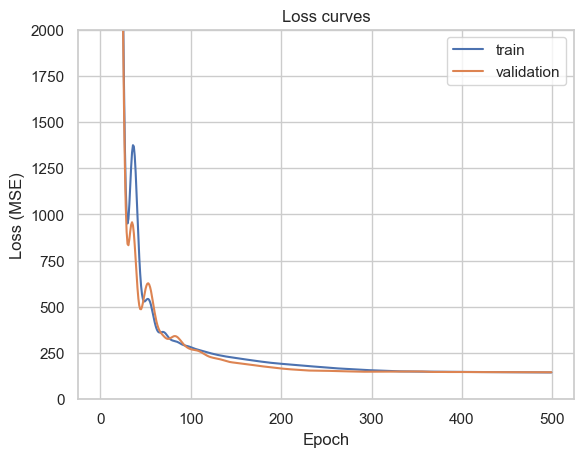

In [16]:
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="validation")
plt.ylim(0, 2000)                  # the first epochs are huge; zoom in on the rest
plt.title("Loss curves")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

Both lines go down fast, then flatten, and they **stay close** to each other. That is the **good** shape: no overfitting.

### Step 7: The final exam: test data, and compare with Linear Regression

In [17]:
with torch.no_grad():
    nn_pred = model(X_test_t).numpy().ravel()          # .ravel() = make it one flat list
nn_mae = mean_absolute_error(y_test, nn_pred)

lin = LinearRegression().fit(X_train, y_train)          # Class 18's model, same train data
lin_mae = mean_absolute_error(y_test, lin.predict(X_test))

print("Neural network MAE:   ", round(nn_mae, 1), "lakh")
print("Linear Regression MAE:", round(lin_mae, 1), "lakh")

Neural network MAE:    12.2 lakh
Linear Regression MAE: 11.9 lakh


**The surprise:** the neural network is **about the same** as Linear Regression (both around 12 lakh), or even a little worse.

**Our answer to the dealer:**
> "No, a neural network is not better here. House prices in this data follow a simple straight-line pattern, and Linear Regression already finds it. Linear Regression is also faster, and you can read its slopes. We would choose Linear Regression."

**The big lesson:** neural networks are not magic. They are the best tool for **complex** data: **photos, sound, text**. For a small, simple table, a simple model is often enough. **Always compare with a simple model first.**

Next class we will see where neural networks really win: **images**.

# 🏠 Home Problem: Car prices with a neural network

The used-car showroom from Class 18 asks the **same question**: *"Would a neural network give better prices?"*

Use `cars.csv` (features: `car_age`, `km_thousands`, `engine_cc`; target: `price_lakh`). **Do the same 7 steps as the Class Problem:**

1. Load the data. Make `X` (3 features) and `y`, with `.values`.
2. Split into train / validation / test (60 / 20 / 20) with `random_state=42`. Print the sizes.
3. Scale with `StandardScaler` (fit on train). Make tensors. Reshape `y` to one column.
4. Build `nn.Sequential(nn.Linear(3, 8), nn.ReLU(), nn.Linear(8, 1))`. **Careful: 3 inputs this time!** Use `nn.MSELoss()` and `Adam` with `lr=0.05`. Call `torch.manual_seed(42)` first.
5. Train for 500 epochs. Save the train and validation loss after every epoch.
6. Draw the loss curves (try `plt.ylim(0, 50)`). Which of the 3 shapes is it?
7. Find the test MAE of the network, and of `LinearRegression`. Which is better?

**Bring to the next class:** your notebook, your loss curve, and 2 or 3 sentences for the showroom.

In [18]:
# Write your code here

# Home Practice: Interview-Style Questions

1. What is a tensor? How is it different from a NumPy array?
2. What does `loss.backward()` do?
3. Name the 5 steps of the training loop, and say what each one does.
4. Why do we call `optimizer.zero_grad()`?
5. What is the difference between validation data and test data?
6. Draw (or describe) a loss curve that shows overfitting.
7. A neural network and a Linear Regression get the same error. Which one would you choose, and why?

# Key Takeaways

- A **tensor** = PyTorch's array. It can find **gradients** for us.
- `loss.backward()` = **backpropagation**, automatic, for every weight.
- `nn.Linear` = a layer of neurons. `nn.Sequential` = layers in a row.
- The training loop: **predict → loss → zero_grad → backward → step**.
- Use **3 parts**: train (learn), validation (mock exam during training), test (final exam, once).
- **Loss curves** show good training, overfitting, or a learning rate that is too big.
- Neural networks shine on **images, sound and text**. On simple tables, **compare with a simple model first**.

**Next class:** CNNs: neural networks that can **see** images.